## Python - Tratamento e Análise exploratória

In [370]:
# importando as bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as srn

In [371]:
# importando o dataset
df = pd.read_csv('Campe_Supply_Corrompido.csv')
df.head(10)

,UNNAMED: 0,data da venda,SETOR,PRODUTO,VENDEDOR,região,ESTADO,cliente,FATURAMENTO,margem de lucro,LUCRO,coluna_inutil_0,coluna_inutil_1
0,NaN,2035-01-01 00:00:00,Carnes,kuína,Amaral,Sudeste,Minas Gerais,Atacado,"633,45","0,13","82,3485",PvlTk,SvWK1
1,NaN,2035-01-01 00:00:00,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,"611,4","0,07","42,798",4ZBrt,gwduN
2,NaN,2035-01-01 00:00:00,Congelados,Sorvete,Leo,Nordeste,NaN,Atacarejo,"721,52","0,08",NaN,Mc6m1,NFY0g
3,NaN,2035-01-01 00:00:00,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,"679,39",0.09,"61,1451",ROb74,QDXmd
4,NaN,2035-01-01 00:00:00,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,tarejo,964.52,"0,19","183,2588",n8NR2,Ml1t1
5,NaN,2035-01-01 00:00:00,Latícinio,Coalhada,Leo,Nordeste,Rio Grande do Norte,Attcarejo,"565,7","0,08","45,256",9ZNcS,skEvZ
6,NaN,2035-01-01 00:00:00,Cvrnes,Frango,Vanessa,Nordeste,Rio Grande do Norte,Atacarejo,"721,01",0.05,"36,0505",IDzv5,IXSeY
7,NaN,2035-01-01 00:00:00,Carnes,Bovina,Vanessa,Sul,Rio Grande do Sul,Atacado,"649,4",0.11,"71,434",gineL,YohO9
8,NaN,2035-01-02 00:00:00,Latícinio,Coalhada,NaN,Sudeste,Minas Gerais,Atacarejo,"789,01","0,19",149.9119,Xbzks,LDKbJ
9,NaN,NaN,Latícinio,Queijo,Daniele,Nordeste,Bahia,Atacado,"574,3","0,05","28,715",wa9bD,prMxB


### Iniciando Análise Exploratória

In [372]:
# Padronizando os nomes das colunas
df.columns = ["Sem nome", "Data da Venda", "Setor", "Produto", "Vendedor", "Região", "Estado", "Cliente", "Faturamento", "Margem de Lucro", "Lucro", "Inutil1", "Inutil2"]

In [373]:
df.head(10)

,Sem nome,Data da Venda,Setor,Produto,Vendedor,Região,Estado,Cliente,Faturamento,Margem de Lucro,Lucro,Inutil1,Inutil2
0,NaN,2035-01-01 00:00:00,Carnes,kuína,Amaral,Sudeste,Minas Gerais,Atacado,"633,45","0,13","82,3485",PvlTk,SvWK1
1,NaN,2035-01-01 00:00:00,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,"611,4","0,07","42,798",4ZBrt,gwduN
2,NaN,2035-01-01 00:00:00,Congelados,Sorvete,Leo,Nordeste,NaN,Atacarejo,"721,52","0,08",NaN,Mc6m1,NFY0g
3,NaN,2035-01-01 00:00:00,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,"679,39",0.09,"61,1451",ROb74,QDXmd
4,NaN,2035-01-01 00:00:00,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,tarejo,964.52,"0,19","183,2588",n8NR2,Ml1t1
5,NaN,2035-01-01 00:00:00,Latícinio,Coalhada,Leo,Nordeste,Rio Grande do Norte,Attcarejo,"565,7","0,08","45,256",9ZNcS,skEvZ
6,NaN,2035-01-01 00:00:00,Cvrnes,Frango,Vanessa,Nordeste,Rio Grande do Norte,Atacarejo,"721,01",0.05,"36,0505",IDzv5,IXSeY
7,NaN,2035-01-01 00:00:00,Carnes,Bovina,Vanessa,Sul,Rio Grande do Sul,Atacado,"649,4",0.11,"71,434",gineL,YohO9
8,NaN,2035-01-02 00:00:00,Latícinio,Coalhada,NaN,Sudeste,Minas Gerais,Atacarejo,"789,01","0,19",149.9119,Xbzks,LDKbJ
9,NaN,NaN,Latícinio,Queijo,Daniele,Nordeste,Bahia,Atacado,"574,3","0,05","28,715",wa9bD,prMxB


In [374]:
#Verificando o tamanho do dataset
df.shape

(1690, 13)

In [375]:
#Verificando tipos de dados e contagem de não-nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1690 entries, 0 to 1689
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Sem nome         31 non-null     object
 1   Data da Venda    1606 non-null   object
 2   Setor            1604 non-null   object
 3   Produto          1607 non-null   object
 4   Vendedor         1608 non-null   object
 5   Região           1606 non-null   object
 6   Estado           1605 non-null   object
 7   Cliente          1603 non-null   object
 8   Faturamento      1602 non-null   object
 9   Margem de Lucro  1610 non-null   object
 10  Lucro            1602 non-null   object
 11  Inutil1          1690 non-null   object
 12  Inutil2          1690 non-null   object
dtypes: object(13)
memory usage: 171.8+ KB


O dataset possui colunas inúteis que deverão ser excluídas, como "Sem nome", "Inutil1" e "Inutil2". <p>
Também possui valores nulos em quase todas as colunas, exceto nas colunas inúteis que serão excluídas. <p>
Todas as colunas estão com objeto até as colunas que deveriam ser numéricas como por exemplo faturamento.

#### Inspecionando a coluna Data da Venda

In [376]:
#Verificando quantos valores nulos existem na coluna "Data da Venda"

df["Data da Venda"].isnull().sum()

84

A coluna Data da Venda possui 84 valores nulos que serão tratados

#### Inspecionando a coluna Setor

In [377]:
#Verificando quantos valores nulos existem na coluna "Setor"

df["Setor"].isnull().sum()

86

In [378]:
# Verificando quais categorias existem na coluna "Setor"

df["Setor"].value_counts(dropna=False)

Setor
Congelados    374
Latícinio     373
Bebidas       361
Carnes        346
NaN            86
             ... 
Latíconio       1
Lattcinio       1
Carves          1
Cobgelados      1
earnes          1
Name: count, Length: 140, dtype: int64

A coluna Setor possui 86 valores nulos e 140 variantes de valores onde alguns estão com erro de digitação como por exemplo Carves e earnes

#### Inspecionando a coluna Produto

In [379]:
# Verificando quantos valores nulos existem na coluna "Produto"

df["Produto"].isnull().sum()

83

In [380]:
# Verificando quais categorias existem na coluna "Produto"

df["Produto"].value_counts(dropna=False)

Produto
Queijo           222
Sorvete          216
Frango           155
Refrigerantes    154
Cervejas         152
                ... 
Sulos              1
Pizta              1
Lhite              1
Sprvete            1
Clalhada           1
Name: count, Length: 153, dtype: int64

A coluna Produto possui 83 valores nulos e 153 variantes de valores onde alguns estão com erro de digitação como por exemplo Sprvete e Lhite

#### Inspecionando a coluna Vendedor

In [381]:
# Verificando quantos valores nulos existem na coluna "Vendedor"

df["Vendedor"].isnull().sum()

82

In [382]:
# Verificando quantos valores diferentes existem na coluna "Vendedor"

df["Vendedor"].value_counts(dropna=False)

Vendedor
Vanessa    443
Amaral     317
Leo        235
Daniele    218
Jonas      116
          ... 
Jotas        1
Vanissa      1
mvandro      1
Dbniele      1
Evtndro      1
Name: count, Length: 153, dtype: int64

A coluna Vendedor possui 82 valores nulos e 153 variantes de valores onde alguns estão com erro de digitação como por exemplo Dbniele e Evtndro

In [383]:
df.head()

,Sem nome,Data da Venda,Setor,Produto,Vendedor,Região,Estado,Cliente,Faturamento,Margem de Lucro,Lucro,Inutil1,Inutil2
0,NaN,2035-01-01 00:00:00,Carnes,kuína,Amaral,Sudeste,Minas Gerais,Atacado,"633,45","0,13","82,3485",PvlTk,SvWK1
1,NaN,2035-01-01 00:00:00,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,"611,4","0,07","42,798",4ZBrt,gwduN
2,NaN,2035-01-01 00:00:00,Congelados,Sorvete,Leo,Nordeste,NaN,Atacarejo,"721,52","0,08",NaN,Mc6m1,NFY0g
3,NaN,2035-01-01 00:00:00,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,"679,39",0.09,"61,1451",ROb74,QDXmd
4,NaN,2035-01-01 00:00:00,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,tarejo,964.52,"0,19","183,2588",n8NR2,Ml1t1


#### inspecionando a coluna Região

In [384]:
# Verificando quantos valores nulos existem na coluna "Região"

df["Região"].isnull().sum()

84

In [385]:
# Verificando quantos valores diferentes existem na coluna "Região"

df["Região"].value_counts(dropna=False)

Região
Sudeste     506
Nordeste    478
Sul         463
NaN          84
mul           4
           ... 
Spl           1
Suduste       1
Nordiste      1
Suveste       1
lul           1
Name: count, Length: 128, dtype: int64

A coluna Região possui 84 valores nulos e 128 variantes de valores onde alguns estão com erro de digitação como por exemplo Spl e lul

#### inspecionando a coluna Estado

In [386]:
# Verificando quantos valores nulos existem na coluna "Estado"

df["Estado"].isnull().sum()

85

In [387]:
# Verificando quantos valores diferentes existem na coluna "Estado"

df["Estado"].value_counts(dropna=False)

Estado
Rio de Janeiro         171
Minas Gerais           170
Bahia                  166
São Paulo              164
Rio Grande do Norte    164
                      ... 
RiobGrande do Norte      1
Minas ferais             1
Riovde Janeiro           1
Rio Grande dk Sul        1
Rio de Janepro           1
Name: count, Length: 161, dtype: int64

A coluna Estado possui 85 valores nulos e 161 variantes de valores onde alguns estão com erro de digitação como por exemplo RiobGrande do Norte e Rio Grande dk Sul

#### inspecionando a coluna Cliente


In [388]:
# Verificando quantos valores nulos existem na coluna "Cliente"

df["Cliente"].isnull().sum()

87

In [389]:
# Verificando quantos valores diferentes existem na coluna "Cliente"

df["Cliente"].value_counts(dropna=False)

Cliente
Atacarejo    482
Varejo       475
Atacado      471
NaN           87
Atacedo        3
            ... 
Atagarejo      1
zarejo         1
Atjcarejo      1
Axacarejo      1
Varevo         1
Name: count, Length: 150, dtype: int64

A coluna Cliente possui 87 valores nulos e 150 variantes de valores onde alguns estão com erro de digitação como por exemplo Atacarejo e Atjcarejo 

In [390]:
df.head()

,Sem nome,Data da Venda,Setor,Produto,Vendedor,Região,Estado,Cliente,Faturamento,Margem de Lucro,Lucro,Inutil1,Inutil2
0,NaN,2035-01-01 00:00:00,Carnes,kuína,Amaral,Sudeste,Minas Gerais,Atacado,"633,45","0,13","82,3485",PvlTk,SvWK1
1,NaN,2035-01-01 00:00:00,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,"611,4","0,07","42,798",4ZBrt,gwduN
2,NaN,2035-01-01 00:00:00,Congelados,Sorvete,Leo,Nordeste,NaN,Atacarejo,"721,52","0,08",NaN,Mc6m1,NFY0g
3,NaN,2035-01-01 00:00:00,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,"679,39",0.09,"61,1451",ROb74,QDXmd
4,NaN,2035-01-01 00:00:00,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,tarejo,964.52,"0,19","183,2588",n8NR2,Ml1t1


#### Inspecionando a coluna Faturamento

In [391]:
df['Faturamento'].describe()

count      1602
unique     1451
top       927,1
freq          3
Name: Faturamento, dtype: object

In [392]:
# Os valores não estão como numéricos, então vou converte-los para conseguir fazer a análise deles.

df['Faturamento'] = pd.to_numeric(df['Faturamento'].str.replace(',', '.'), errors='coerce')
df['Faturamento'].describe()

count    1569.000000
mean      896.626673
std       400.539175
min       520.360000
25%       670.190000
50%       799.530000
75%       948.200000
max      8581.600000
Name: Faturamento, dtype: float64

In [393]:
# Verificando quantos valores nulos existem na coluna "Faturamento"

df['Faturamento'].isnull().sum()

121

Text(0.5, 1.0, 'Boxplot do Faturamento')

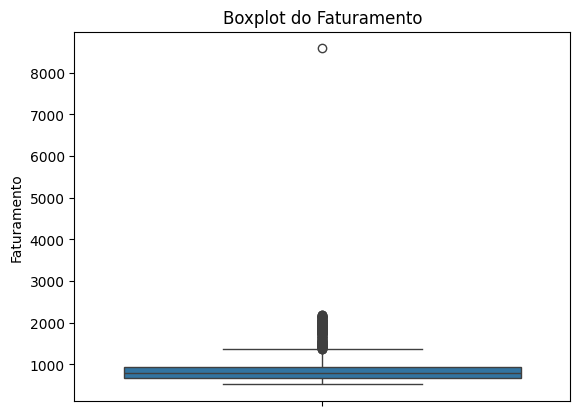

In [394]:
srn.boxplot(df['Faturamento']).set_title('Boxplot do Faturamento')

#### Inspecionando a coluna Margem de Lucro

In [395]:
df['Margem de Lucro'].describe()

count     1610
unique      61
top       0,08
freq       100
Name: Margem de Lucro, dtype: object

In [396]:
# Alterando o tipo de dado da coluna "Margem de Lucro" para numérico

df['Margem de Lucro'] = pd.to_numeric(df['Margem de Lucro'].str.replace(',', '.'), errors='coerce')
df['Margem de Lucro'].describe()

count    1581.000000
mean        0.119311
std         0.043098
min         0.000000
25%         0.080000
50%         0.120000
75%         0.160000
max         0.190000
Name: Margem de Lucro, dtype: float64

In [397]:
# Verificando quantos valores nulos existem na coluna "Margem de Lucro"
df['Margem de Lucro'].isnull().sum()

109

Text(0.5, 1.0, 'Boxplot da Margem de Lucro')

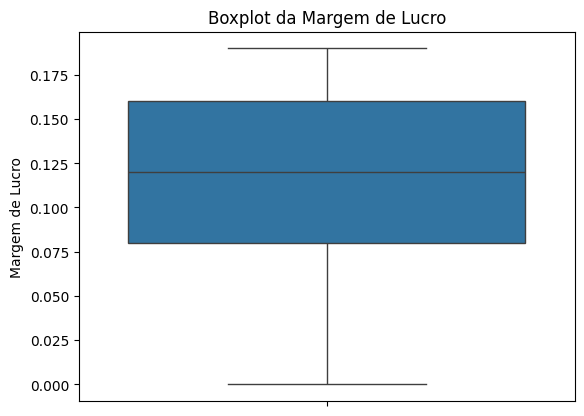

In [398]:
srn.boxplot(df['Margem de Lucro']).set_title('Boxplot da Margem de Lucro')

#### Inspecionando a coluna Lucro

In [399]:
df['Lucro'].describe()

count       1602
unique      1461
top       45,494
freq           3
Name: Lucro, dtype: object

In [400]:
# Convertendo a coluna "Lucro" para numérico

df['Lucro'] = pd.to_numeric(df['Lucro'].str.replace(',', '.'), errors='coerce')
df['Lucro'].describe()

count    1.570000e+03
mean     3.474494e+03
std      9.686204e+04
min      2.669350e+01
25%      6.545850e+01
50%      9.524290e+01
75%      1.306109e+02
max      3.260000e+06
Name: Lucro, dtype: float64

In [401]:
# Verificando quantos valores nulos existem na coluna "Margem de Lucro"
df['Margem de Lucro'].isnull().sum()

109

Text(0.5, 1.0, 'Boxplot do Lucro')

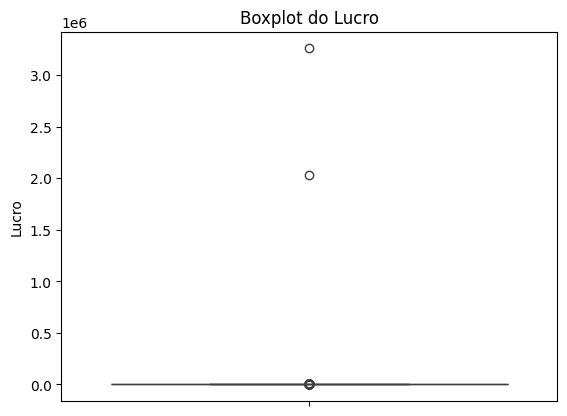

In [402]:
srn.boxplot(df['Lucro']).set_title('Boxplot do Lucro')

In [403]:
df.head(10)

,Sem nome,Data da Venda,Setor,Produto,Vendedor,Região,Estado,Cliente,Faturamento,Margem de Lucro,Lucro,Inutil1,Inutil2
0,NaN,2035-01-01 00:00:00,Carnes,kuína,Amaral,Sudeste,Minas Gerais,Atacado,633.45,0.13,82.3485,PvlTk,SvWK1
1,NaN,2035-01-01 00:00:00,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,611.40,0.07,42.7980,4ZBrt,gwduN
2,NaN,2035-01-01 00:00:00,Congelados,Sorvete,Leo,Nordeste,NaN,Atacarejo,721.52,0.08,NaN,Mc6m1,NFY0g
3,NaN,2035-01-01 00:00:00,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,679.39,0.09,61.1451,ROb74,QDXmd
4,NaN,2035-01-01 00:00:00,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,tarejo,964.52,0.19,183.2588,n8NR2,Ml1t1
5,NaN,2035-01-01 00:00:00,Latícinio,Coalhada,Leo,Nordeste,Rio Grande do Norte,Attcarejo,565.70,0.08,45.2560,9ZNcS,skEvZ
6,NaN,2035-01-01 00:00:00,Cvrnes,Frango,Vanessa,Nordeste,Rio Grande do Norte,Atacarejo,721.01,0.05,36.0505,IDzv5,IXSeY
7,NaN,2035-01-01 00:00:00,Carnes,Bovina,Vanessa,Sul,Rio Grande do Sul,Atacado,649.40,0.11,71.4340,gineL,YohO9
8,NaN,2035-01-02 00:00:00,Latícinio,Coalhada,NaN,Sudeste,Minas Gerais,Atacarejo,789.01,0.19,149.9119,Xbzks,LDKbJ
9,NaN,NaN,Latícinio,Queijo,Daniele,Nordeste,Bahia,Atacado,574.30,0.05,28.7150,wa9bD,prMxB


### Tratamento dos Dados

In [404]:
# 1º

# Removendo colunas irrelevantes
df = df.drop(columns=["Sem nome", "Inutil1", "Inutil2"])

df.head()

,Data da Venda,Setor,Produto,Vendedor,Região,Estado,Cliente,Faturamento,Margem de Lucro,Lucro
0,2035-01-01 00:00:00,Carnes,kuína,Amaral,Sudeste,Minas Gerais,Atacado,633.45,0.13,82.3485
1,2035-01-01 00:00:00,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,611.40,0.07,42.7980
2,2035-01-01 00:00:00,Congelados,Sorvete,Leo,Nordeste,NaN,Atacarejo,721.52,0.08,NaN
3,2035-01-01 00:00:00,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,679.39,0.09,61.1451
4,2035-01-01 00:00:00,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,tarejo,964.52,0.19,183.2588


In [405]:
# 2º Tratando a coluna "Data da Venda" para o formato brasileiro

df["Data da Venda"] = pd.to_datetime(df["Data da Venda"], errors='coerce').dt.strftime('%d/%m/%Y')

df.head()

,Data da Venda,Setor,Produto,Vendedor,Região,Estado,Cliente,Faturamento,Margem de Lucro,Lucro
0,01/01/2035,Carnes,kuína,Amaral,Sudeste,Minas Gerais,Atacado,633.45,0.13,82.3485
1,01/01/2035,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,611.40,0.07,42.7980
2,01/01/2035,Congelados,Sorvete,Leo,Nordeste,NaN,Atacarejo,721.52,0.08,NaN
3,01/01/2035,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,679.39,0.09,61.1451
4,01/01/2035,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,tarejo,964.52,0.19,183.2588


In [406]:
df['Data da Venda'].isnull().sum()

84

In [407]:
# Preenchendo os valores nulos usando a data anterior e a posterior caso o primeiro seja nulo

df["Data da Venda"] = df["Data da Venda"].ffill().bfill()

In [408]:
df['Data da Venda'].isnull().sum()

0

In [409]:
# 3º Tratando a coluna "Setor"

import difflib

# Substituindo os valores incorretos pelos corretos usando a função get_close_matches do módulo difflib

setores_oficiais = ['Congelados', 'Latícinio', 'Bebidas', 'Carnes']

def corrigir_setor(valor):
    
    if pd.isna(valor):
        return valor
    
    correspondencia = difflib.get_close_matches(str(valor), setores_oficiais, n=1, cutoff=0.6)
    
    if correspondencia:
        return correspondencia[0]
    else:
        return valor

df['Setor'] = df['Setor'].apply(corrigir_setor)

print(df['Setor'].value_counts(dropna=False))

Setor
Latícinio     408
Congelados    402
Bebidas       402
Carnes        392
NaN            86
Name: count, dtype: int64


In [410]:
df['Setor'].isnull().sum()

86

In [411]:
# Substituindo os valores nulos da coluna "Setor" pela moda

moda_setor = df["Setor"].mode()[0]
df["Setor"] = df["Setor"].fillna(moda_setor)

In [412]:
df['Setor'].isnull().sum()

0

In [413]:
# 4º Tratando a coluna "Produto"

produtos_oficiais = ['Sorvete', 'Queijo', 'Cervejas', 'Bovina','Refrigerantes','Frango','Lasanha','Sucos','Suína','Leite','Coalhada','Pizza']

# Substituindo os valores incorretos pelos corretos usando a função get_close_matches do módulo difflib

def corrigir_produto(valor):
    
    if pd.isna(valor): 
        return valor
    
    match = difflib.get_close_matches(str(valor), produtos_oficiais, n=1, cutoff=0.5)
    
    return match[0] if match else valor

df['Produto'] = df['Produto'].apply(corrigir_produto)

# Tratando os valores nulos preenchendo com a moda

df['Produto'] = df['Produto'].fillna(df['Produto'].mode()[0])

print(df['Produto'].value_counts(dropna=False))

Produto
Queijo           319
Sorvete          236
Refrigerantes    172
Frango           169
Cervejas         169
Bovina           153
Leite            139
Lasanha           85
Suína             81
Pizza             79
Sucos             67
Coalhada          21
Name: count, dtype: int64


In [414]:
df['Produto'].isnull().sum()

0

In [415]:
# 5º Tratando a coluna "Vendedor"

vendedores_oficiais = ['Amaral', 'Leo', 'Daniele', 'Vanessa', 'Evandro', 'Jonas']

# Substituindo os valores incorretos pelos corretos usando a função get_close_matches do módulo difflib

def corrigir_vendedor(valor):
    
    if pd.isna(valor):
        return valor
    match = difflib.get_close_matches(str(valor), vendedores_oficiais, n=1, cutoff=0.5)
    
    return match[0] if match else valor

df['Vendedor'] = df['Vendedor'].apply(corrigir_vendedor)

# Preenchendo os valores nulos da coluna "Vendedor" com a moda

df['Vendedor'] = df['Vendedor'].fillna(df['Vendedor'].mode()[0])

print(df['Vendedor'].value_counts(dropna=False))

Vendedor
Vanessa    568
Amaral     356
Leo        259
Daniele    246
Jonas      135
Evandro    126
Name: count, dtype: int64


In [416]:
df['Vendedor'].isnull().sum()

0

In [417]:
# 6º Tratando a coluna "Região"

regioes_oficiais = ['Sudeste', 'Sul', 'Nordeste', 'Centro-Oeste','Norte']

# Substituindo os valores incorretos pelos corretos usando a função get_close_matches do módulo difflib

def corrigir_regiao(valor):
    
    if pd.isna(valor): 
        return valor
    
    match = difflib.get_close_matches(str(valor), regioes_oficiais, n=1, cutoff=0.5)
    
    return match[0] if match else valor

df['Região'] = df['Região'].apply(corrigir_regiao)

# Preenchendo os valores nulos da coluna "Região" com a moda

df['Região'] = df['Região'].fillna(df['Região'].mode()[0])

print(df['Região'].value_counts(dropna=False))

Região
Sudeste     642
Nordeste    537
Sul         511
Name: count, dtype: int64


In [418]:
df['Região'].isnull().sum()

0

In [419]:
# 7º Tratando a coluna "Estado"

estados_oficiais = ['Rio de Janeiro', 'Minas Gerais', 'Bahia', 'São Paulo','Rio Grande do Norte','Rio Grande do Sul', 'Sergipe', 'Santa Catarina','Paraná', 'Mato Grosso', 'Mato Grosso do Sul', 'Goiás', 'Distrito Federal','Alagoas','Ceará','Pernambuco','Paraíba','Espírito Santo','Amazonas','Roraima','Amapá','Tocantins','Pará','Maranhão']

# Substituindo os valores incorretos pelos corretos usando a função get_close_matches do módulo difflib

def corrigir_estado(valor):
    
    if pd.isna(valor): 
        return valor
    
    match = difflib.get_close_matches(str(valor), estados_oficiais, n=1, cutoff=0.5)
    
    return match[0] if match else valor

df['Estado'] = df['Estado'].apply(corrigir_estado)

# Preenchendo os valores nulos da coluna "Estado" com a moda

df['Estado'] = df['Estado'].fillna(df['Estado'].mode()[0])

print(df['Estado'].value_counts(dropna=False))

Estado
Rio Grande do Norte    274
Minas Gerais           186
Rio de Janeiro         186
Bahia                  185
Rio Grande do Sul      180
São Paulo              178
Paraná                 173
Sergipe                168
Santa Catarina         160
Name: count, dtype: int64


In [420]:
df['Estado'].isnull().sum()

0

In [422]:
# 8º Tratando a coluna "Cliente"

clientes_oficiais = ['Atacado', 'Varejo', 'Atacarejo']

# Substituindo os valores incorretos pelos corretos usando a função get_close_matches do módulo difflib

def corrigir_cliente(valor):
    
    if pd.isna(valor): 
        return valor
    
    match = difflib.get_close_matches(str(valor), clientes_oficiais, n=1, cutoff=0.5)
    
    return match[0] if match else valor

df['Cliente'] = df['Cliente'].apply(corrigir_cliente)

# Preenchendo os valores nulos da coluna "Cliente" com a moda

df['Cliente'] = df['Cliente'].fillna(df['Cliente'].mode()[0])

print(df['Cliente'].value_counts(dropna=False))

Cliente
Varejo       634
Atacarejo    534
Atacado      522
Name: count, dtype: int64


In [423]:
# 9º Tratando as colunas numéricas "Faturamento", "Margem de Lucro" e "Lucro"

colunas_numericas = ['Faturamento', 'Margem de Lucro', 'Lucro']

for coluna in colunas_numericas:
    
    mediana = df[coluna].median()
    
    df[coluna] = df[coluna].fillna(mediana)
    
df.head(15)

,Data da Venda,Setor,Produto,Vendedor,Região,Estado,Cliente,Faturamento,Margem de Lucro,Lucro
0,01/01/2035,Carnes,Suína,Amaral,Sudeste,Minas Gerais,Atacado,633.45,0.13,82.3485
1,01/01/2035,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,611.40,0.07,42.7980
2,01/01/2035,Congelados,Sorvete,Leo,Nordeste,Rio Grande do Norte,Atacarejo,721.52,0.08,95.2429
3,01/01/2035,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,679.39,0.09,61.1451
4,01/01/2035,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,Varejo,964.52,0.19,183.2588
5,01/01/2035,Latícinio,Coalhada,Leo,Nordeste,Rio Grande do Norte,Atacarejo,565.70,0.08,45.2560
6,01/01/2035,Carnes,Frango,Vanessa,Nordeste,Rio Grande do Norte,Atacarejo,721.01,0.05,36.0505
7,01/01/2035,Carnes,Bovina,Vanessa,Sul,Rio Grande do Sul,Atacado,649.40,0.11,71.4340
8,02/01/2035,Latícinio,Coalhada,Vanessa,Sudeste,Minas Gerais,Atacarejo,789.01,0.19,149.9119
9,02/01/2035,Latícinio,Queijo,Daniele,Nordeste,Bahia,Atacado,574.30,0.05,28.7150


In [424]:
df['Faturamento'].isnull().sum()

0

In [425]:
df['Margem de Lucro'].isnull().sum()

0

In [426]:
df['Lucro'].isnull().sum()

0

In [ ]:
# Recalculando a coluna Lucro com base no Faturamento e na Margem de Lucro

df['Lucro'] = df['Faturamento'] * (df['Margem de Lucro'])
df.head(15)

,Data da Venda,Setor,Produto,Vendedor,Região,Estado,Cliente,Faturamento,Margem de Lucro,Lucro
0,01/01/2035,Carnes,Suína,Amaral,Sudeste,Minas Gerais,Atacado,633.45,0.13,82.3485
1,01/01/2035,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,611.40,0.07,42.7980
2,01/01/2035,Congelados,Sorvete,Leo,Nordeste,Rio Grande do Norte,Atacarejo,721.52,0.08,57.7216
3,01/01/2035,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,679.39,0.09,61.1451
4,01/01/2035,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,Varejo,964.52,0.19,183.2588
5,01/01/2035,Latícinio,Coalhada,Leo,Nordeste,Rio Grande do Norte,Atacarejo,565.70,0.08,45.2560
6,01/01/2035,Carnes,Frango,Vanessa,Nordeste,Rio Grande do Norte,Atacarejo,721.01,0.05,36.0505
7,01/01/2035,Carnes,Bovina,Vanessa,Sul,Rio Grande do Sul,Atacado,649.40,0.11,71.4340
8,02/01/2035,Latícinio,Coalhada,Vanessa,Sudeste,Minas Gerais,Atacarejo,789.01,0.19,149.9119
9,02/01/2035,Latícinio,Queijo,Daniele,Nordeste,Bahia,Atacado,574.30,0.05,28.7150


#### Salvando o DataFrame tratado

In [429]:
df.to_csv('Campe_Supply_Tratado.csv', index=False, encoding='utf-8')